# Generative Adversarial Networks #

First make sure we have a GPU available, or this will take a really long time to train. If you don't, refer to https://www.tensorflow.org/install/gpu

In [1]:
import tensorflow as tf


# manter a consistência do desempenho
tf.random.set_seed(1)

# confirmar se a gpu está disponível
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


As before, we'll load up the Fashion MNIST dataset, merge it all together since we're not doing train/test, and normalize the data as we did with VAE's:

In [2]:
from tensorflow.keras.datasets import fashion_mnist # importa tensorflow keras

# carregar o dataset fashion mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
import numpy as np # importa a biblioteca numpy

# unir os conjuntos de treino e teste
dataset = np.concatenate([x_train, x_test], axis=0)
# normalizar as imagens
dataset = np.expand_dims(dataset, -1).astype("float32") / 255

Now we will reshape the data to the dimensions needed by the CNN layers, shuffle, and batch it:

In [4]:
BATCH_SIZE = 64

# camadas de convolução trabalham com 3 canais
dataset = np.reshape(dataset, (-1, 28, 28, 1))
# criar um objeto de dataset do tensorflow
dataset = tf.data.Dataset.from_tensor_slices(dataset)
# definir o tamanho do lote para não ler uma imagem por vez
dataset = dataset.shuffle(buffer_size=1024).batch(BATCH_SIZE)

In [5]:
from tensorflow import keras
from tensorflow.keras import layers

# a entrada do gerador é um vetor de ruído
# hiperparametro que necessita de ajuste fino
NOISE_DIM = 150

# projetar modelo gerador com camadas de upsampling
# na prática o gerador usa ativação leaky relu e o discriminador usa relu
generator = keras.models.Sequential([
  keras.layers.InputLayer(input_shape=(NOISE_DIM,)),
  layers.Dense(7*7*256),
  layers.Reshape(target_shape=(7, 7, 256)),
  layers.Conv2DTranspose(256, 3, strides=2, padding="same"),
  layers.LeakyReLU(),
  layers.Conv2DTranspose(128, 3, strides=2, padding="same"),
  layers.LeakyReLU(),
  layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")
])

generator.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,894,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,153 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,780,417 (10.61 MB)

 Trainable params: 2,780,417 (10.61 MB)

 Non-trainable params: 0 (0.00 B)

Next we'll make our discriminator model, using two Conv2D layers to downsample before going into a 64-neuron dense layer and a dropout to avoid overfitting. Its output is binary, as its job is to classify images as "real" or "fake"... until it can no longer tell the difference.

In [6]:
# projetar o discriminador com camadas de downsampling
discriminator = keras.models.Sequential([
  keras.layers.InputLayer(input_shape=(28, 28, 1)),
  layers.Conv2D(256, 3, activation="relu", strides=2, padding="same"),
  layers.Conv2D(128, 3, activation="relu", strides=2, padding="same"),
  layers.Flatten(),
  layers.Dense(64, activation="relu"),
  layers.Dropout(0.2),
  layers.Dense(1, activation="sigmoid")
])

discriminator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 256)    │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 699,137 (2.67 MB)

 Trainable params: 699,137 (2.67 MB)

 Non-trainable params: 0 (0.00 B)

Set up our optimizers, loss function, and accuracy metrics. Whee, more hyperparameters - getting the learning rates just right on both the generator and discriminator is the key. Otherwise it won't be stable.

In [7]:
# definir taxas de aprendizado diferentes para o gerador e discriminador
# taxas de aprendizado altas afetam muito a estabilidade do jogo
optimizerG = keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.5)
optimizerD = keras.optimizers.Adam(learning_rate=0.00003, beta_1=0.5)

# classificador binário (real ou falso)
lossFn = keras.losses.BinaryCrossentropy(from_logits=True)

# métrica de acurácia
gAccMetric = tf.keras.metrics.BinaryAccuracy()
dAccMetric = tf.keras.metrics.BinaryAccuracy()

OK, let's tie them together. We initially feed our generator gaussian noise. Its "fake" outputs are concatenated to "real" data fed into the discriminator. The discriminator does its best to identify real vs. fake labels. Here we define the training function for the discriminator:

In [8]:
# a ferramenta decoradora permite compilação nativa eficiente no tensorflow
@tf.function
def trainDStep(data):
  # extrair o tamanho atual do lote
  batchSize = tf.shape(data)[0]
  # criar vetor de ruído com distribuição normal gaussiana para o gerador
  noise = tf.random.normal(shape=(batchSize, NOISE_DIM))

  # concatenar os rótulos reais e falsos
  y_true = tf.concat(
    [
      # dados originais são reais, rotulados com 1
      tf.ones(batchSize, 1),
      # dados gerados são falsos, rotulados com 0
      tf.zeros(batchSize, 1)
    ],
    axis=0
  )

  # registrar os gradientes calculados
  with tf.GradientTape() as tape:
    # gerar amostras falsas
    fake = generator(noise)
    # concatenar dados reais e falsos
    x = tf.concat([data, fake], axis=0)
    # verificar se o discriminador detecta as amostras
    y_pred = discriminator(x)
    # calcular a perda
    discriminatorLoss = lossFn(y_true, y_pred)

  # aplicar o passo de retropropagação e atualizar os pesos
  grads = tape.gradient(discriminatorLoss, discriminator.trainable_weights)
  optimizerD.apply_gradients(zip(grads, discriminator.trainable_weights))

  # atualizar a métrica de acurácia
  dAccMetric.update_state(y_true, y_pred)

  # retornar as métricas para visualização
  return {
      "discriminator_loss": discriminatorLoss,
      "discriminator_accuracy": dAccMetric.result()
  }

And now, the training function for the generator. Remember the generator is trying not to get caught, and so it wants to be classified as real. Its loss function is based on how often the discriminator classifies its fake samples as real. This is in tension with the discriminator, which is trying to find fakes.

In [9]:
@tf.function
def trainGStep(data):
  batchSize = tf.shape(data)[0]
  noise = tf.random.normal(shape=(batchSize, NOISE_DIM))
  # treinar o gerador para maximizar a chance de sua saída ser classificada como real
  y_true = tf.ones(batchSize, 1)

  with tf.GradientTape() as tape:
    y_pred = discriminator(generator(noise))
    generatorLoss = lossFn(y_true, y_pred)

  grads = tape.gradient(generatorLoss, generator.trainable_weights)
  optimizerG.apply_gradients(zip(grads, generator.trainable_weights))

  gAccMetric.update_state(y_true, y_pred)

  return {
      "generator_loss": generatorLoss,
      "generator_accuracy": gAccMetric.result()
  }

Let's set up a handy function to visualize generated images as we train:

In [10]:
from matplotlib import pyplot as plt


def plotImages(model):
    images = model(np.random.normal(size=(81, NOISE_DIM)))

    plt.figure(figsize=(9, 9))

    for i, image in enumerate(images):
        plt.subplot(9,9,i+1)
        plt.imshow(np.squeeze(image, -1), cmap="Greys_r")
        plt.axis('off')

    plt.show();

Now it's showtime. Since the adversarial game is a delicate balance, we want to observe the results as training progresses. It may converge and then diverge again; it is very touchy stuff. Here we just go through each batch, train the discriminator, and train the generator each epoch. Every other epoch we'll peek at some generated images to see how they are looking, as the generator learns probability distributions to represent realistic images.

/usr/local/lib/python3.12/dist-packages/keras/src/backend/tensorflow/nn.py:1286: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Sigmoid activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


E:0, Loss G:2.8462, Loss D:0.1253, Acc G:%1.55, Acc D:%97.86


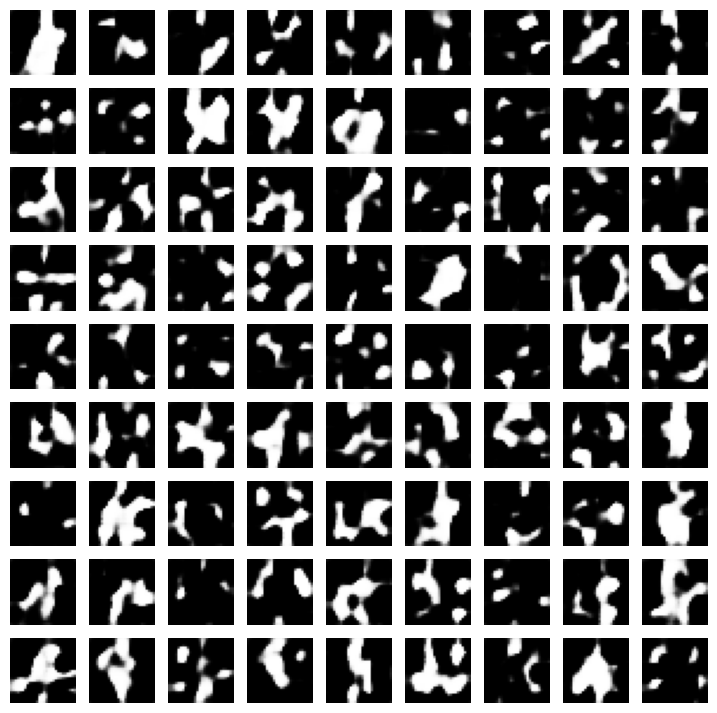

E:1, Loss G:3.0246, Loss D:0.1191, Acc G:%0.82, Acc D:%97.97
E:2, Loss G:3.3033, Loss D:0.1144, Acc G:%0.96, Acc D:%97.66


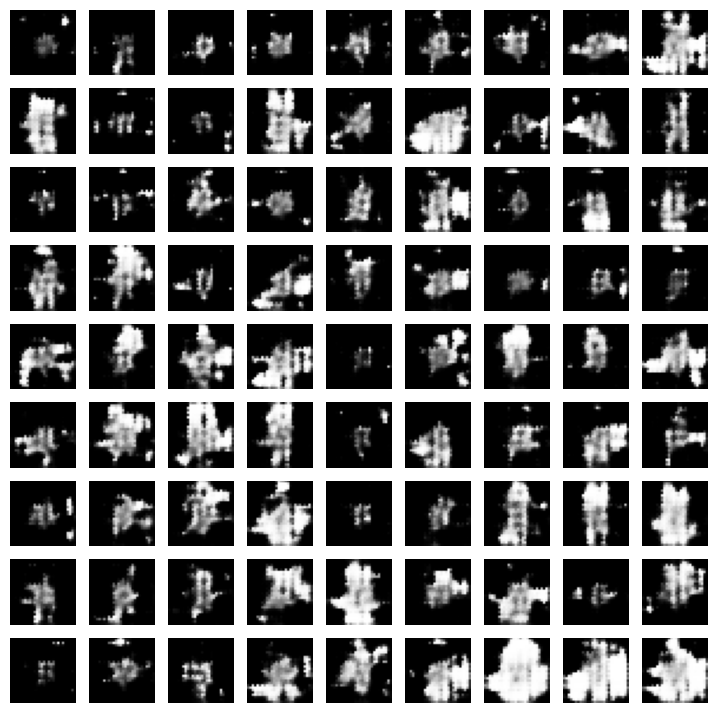

E:3, Loss G:2.4325, Loss D:0.2095, Acc G:%1.37, Acc D:%96.89
E:4, Loss G:1.9993, Loss D:0.3141, Acc G:%2.26, Acc D:%95.40


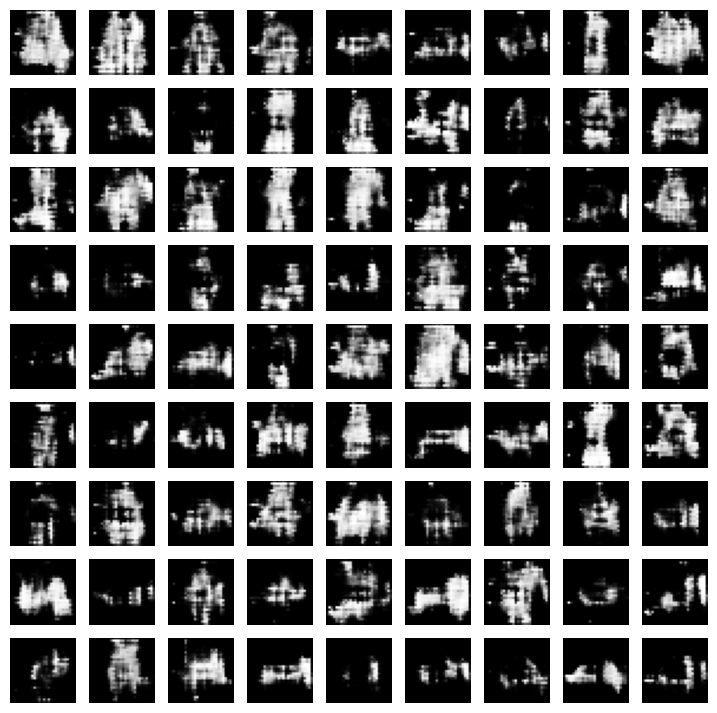

E:5, Loss G:1.8773, Loss D:0.3037, Acc G:%3.30, Acc D:%93.96
E:6, Loss G:1.8815, Loss D:0.2903, Acc G:%3.69, Acc D:%93.36


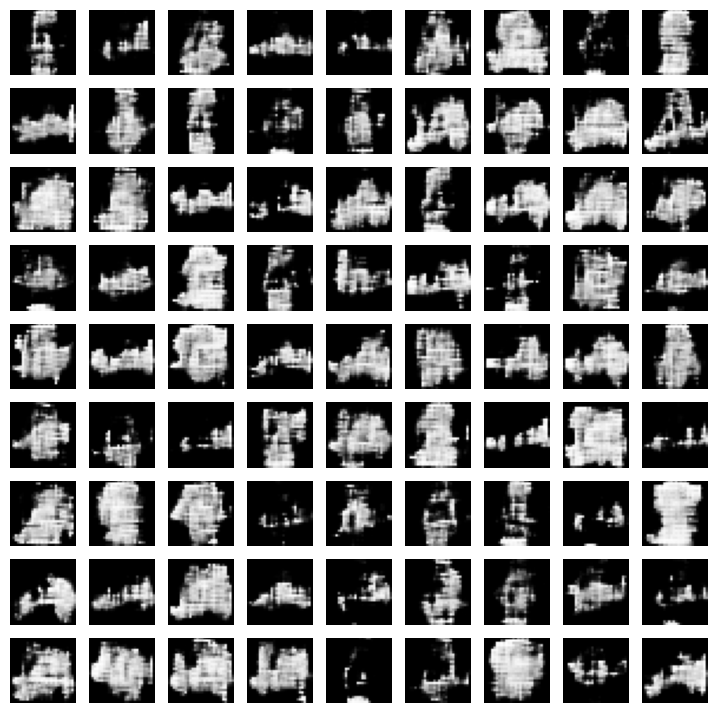

E:7, Loss G:1.8793, Loss D:0.2873, Acc G:%3.94, Acc D:%92.99
E:8, Loss G:1.9146, Loss D:0.2819, Acc G:%4.11, Acc D:%92.71


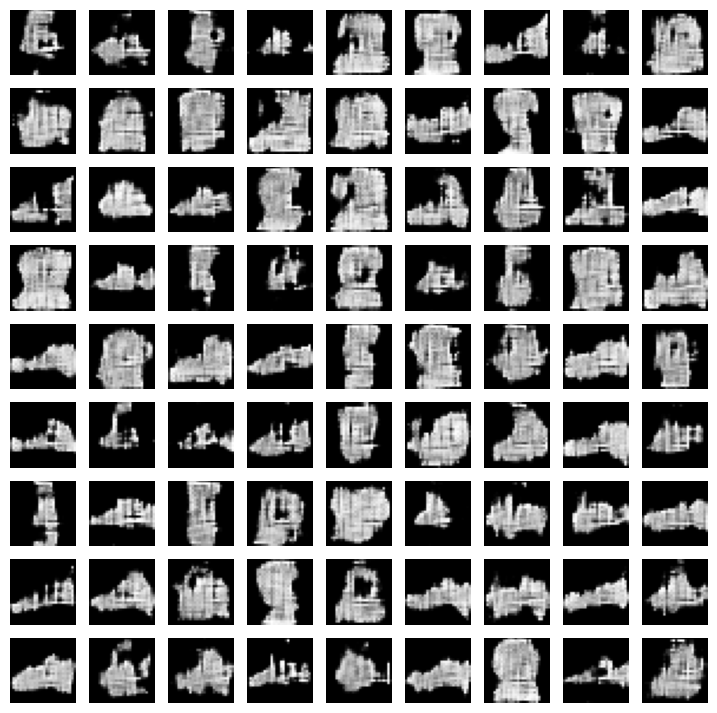

E:9, Loss G:1.8818, Loss D:0.2747, Acc G:%4.20, Acc D:%92.51
E:10, Loss G:1.8869, Loss D:0.2754, Acc G:%4.27, Acc D:%92.34


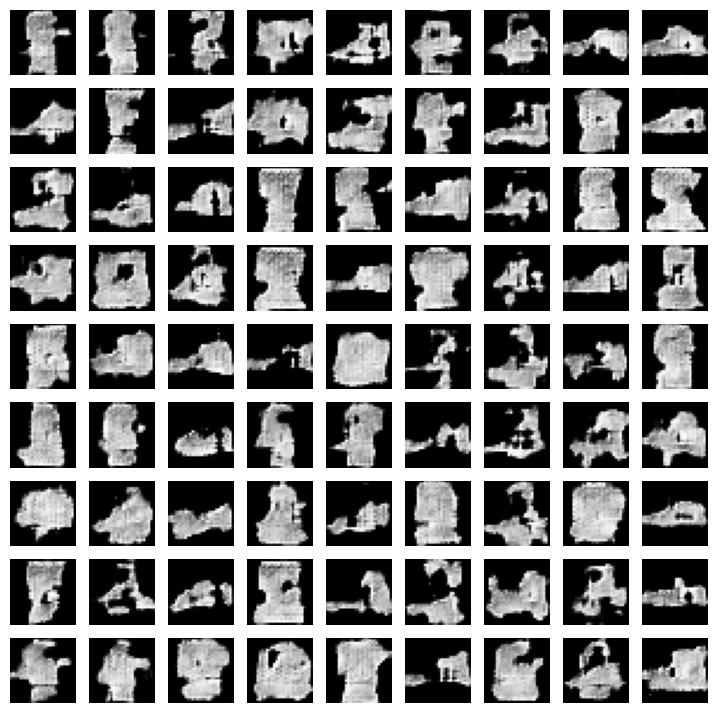

E:11, Loss G:1.9060, Loss D:0.2799, Acc G:%4.35, Acc D:%92.16
E:12, Loss G:1.9888, Loss D:0.2670, Acc G:%4.39, Acc D:%92.00


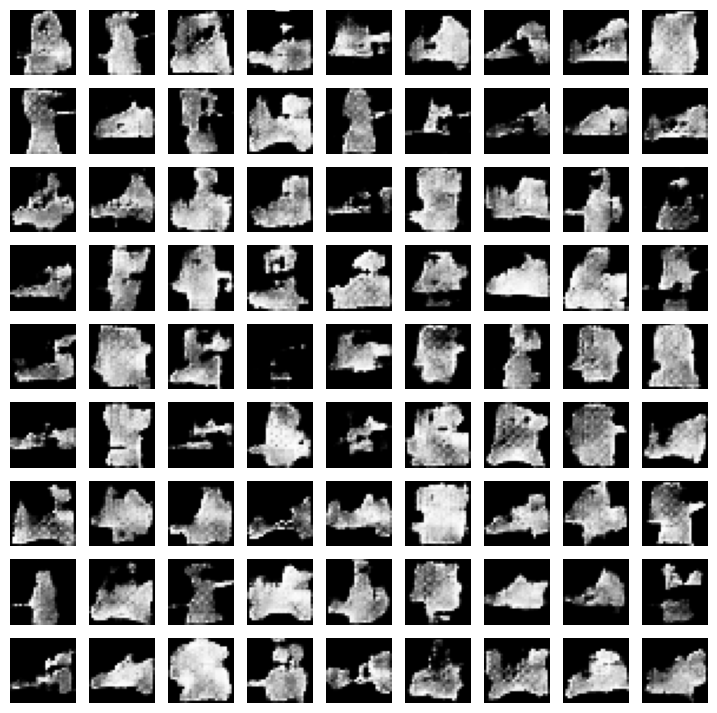

E:13, Loss G:2.0364, Loss D:0.2746, Acc G:%4.41, Acc D:%91.88
E:14, Loss G:2.0793, Loss D:0.2790, Acc G:%4.52, Acc D:%91.72


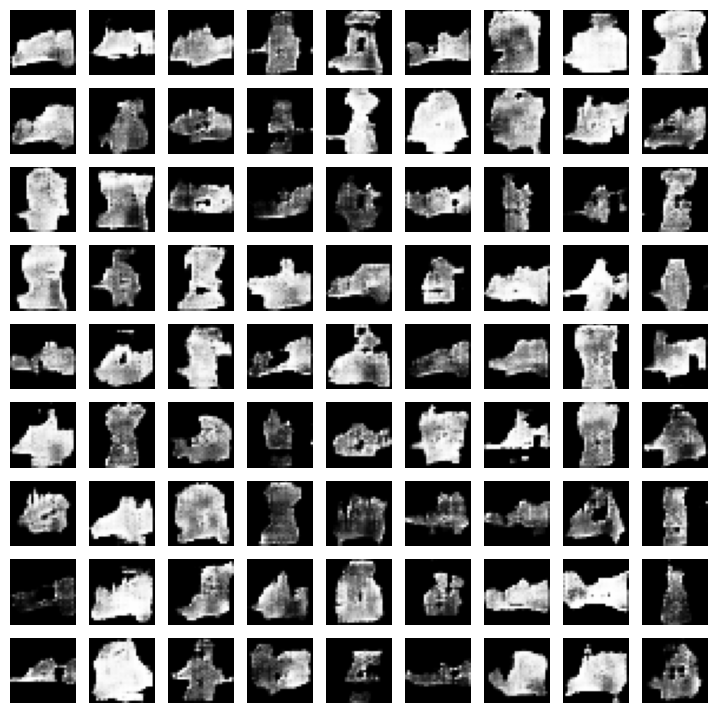

E:15, Loss G:2.0739, Loss D:0.2822, Acc G:%4.66, Acc D:%91.56
E:16, Loss G:2.0807, Loss D:0.2725, Acc G:%4.77, Acc D:%91.43


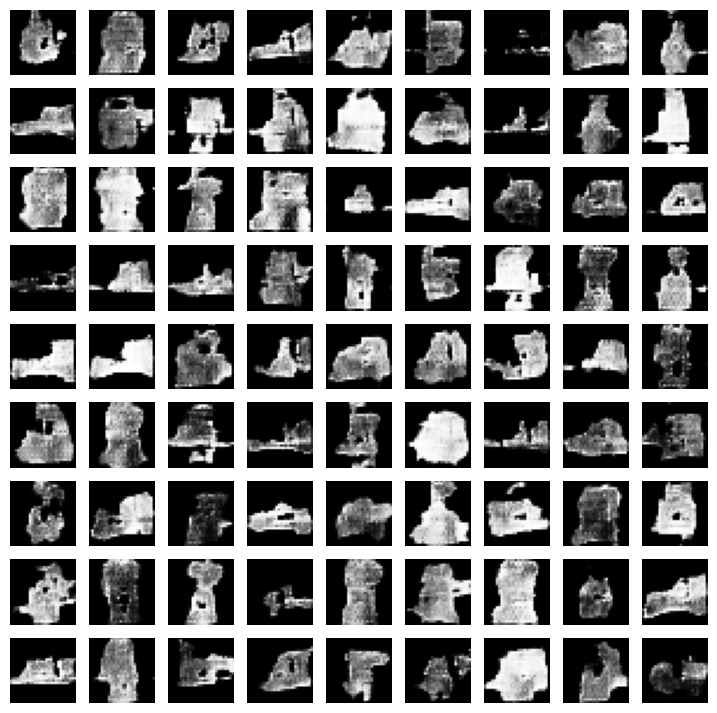

E:17, Loss G:2.1239, Loss D:0.2556, Acc G:%4.82, Acc D:%91.35
E:18, Loss G:2.1593, Loss D:0.2440, Acc G:%4.83, Acc D:%91.32


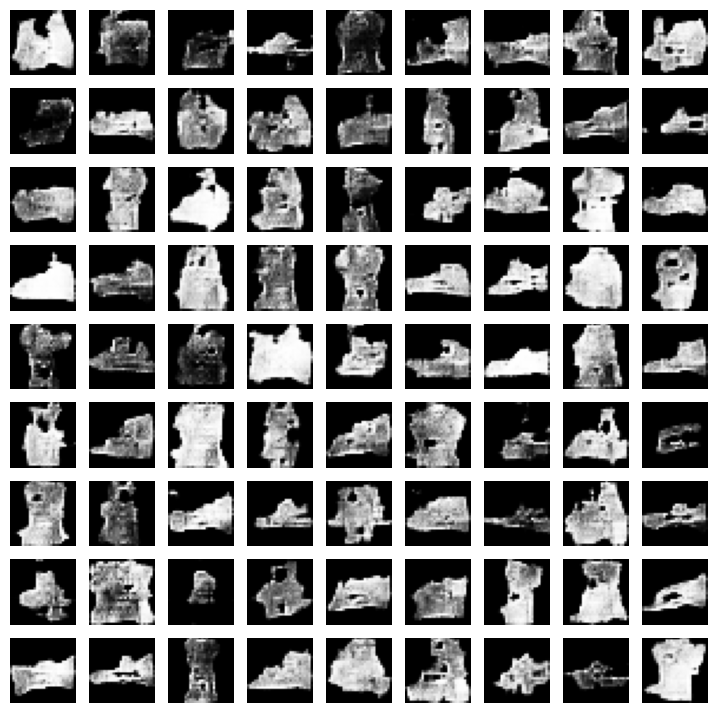

E:19, Loss G:2.1843, Loss D:0.2382, Acc G:%4.81, Acc D:%91.33
E:20, Loss G:2.2040, Loss D:0.2334, Acc G:%4.78, Acc D:%91.34


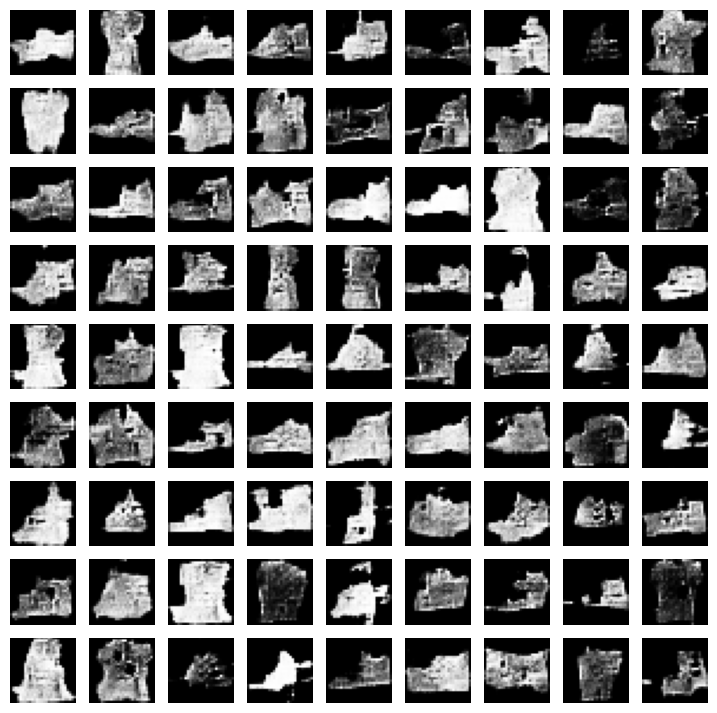

E:21, Loss G:2.2340, Loss D:0.2293, Acc G:%4.75, Acc D:%91.36
E:22, Loss G:2.2407, Loss D:0.2279, Acc G:%4.71, Acc D:%91.38


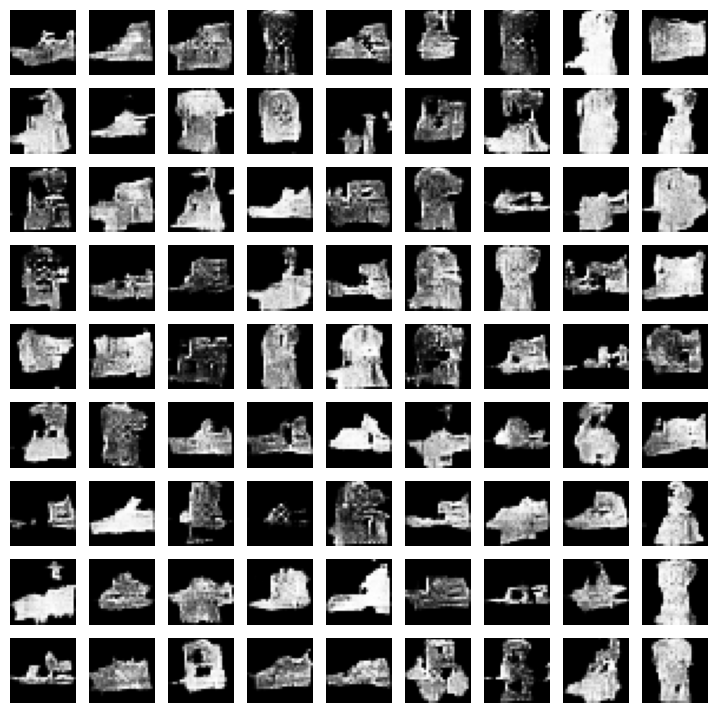

E:23, Loss G:2.2547, Loss D:0.2249, Acc G:%4.68, Acc D:%91.41
E:24, Loss G:2.3066, Loss D:0.2216, Acc G:%4.64, Acc D:%91.44


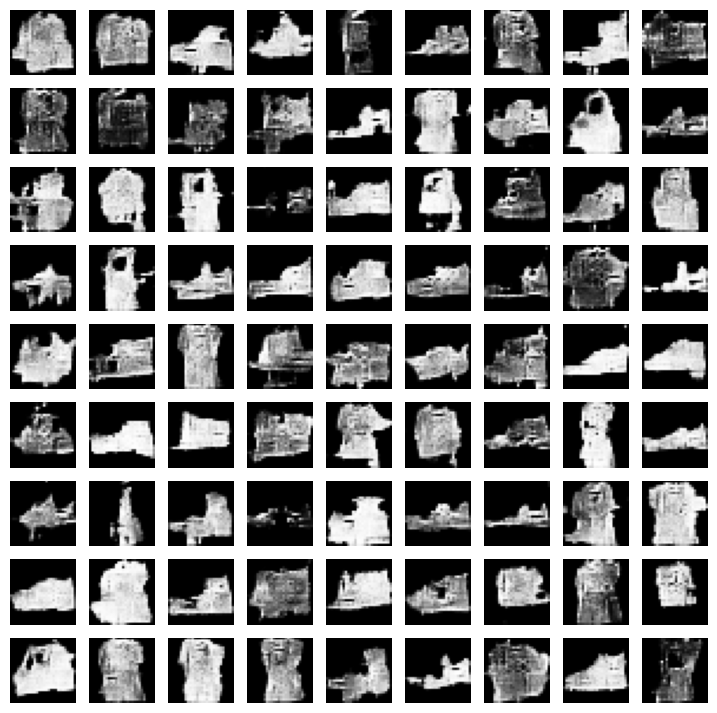

E:25, Loss G:2.3257, Loss D:0.2257, Acc G:%4.61, Acc D:%91.46
E:26, Loss G:2.2898, Loss D:0.2321, Acc G:%4.60, Acc D:%91.47


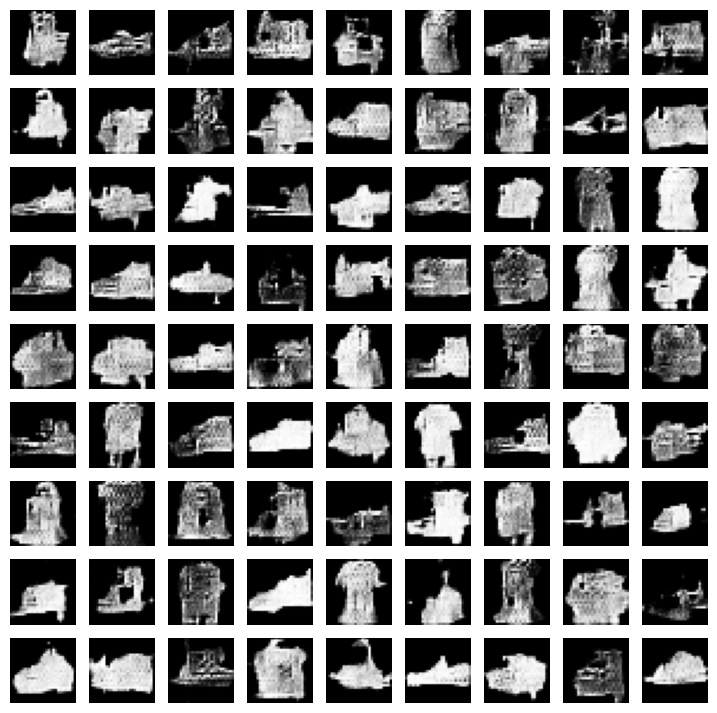

E:27, Loss G:2.2939, Loss D:0.2381, Acc G:%4.60, Acc D:%91.46
E:28, Loss G:2.2972, Loss D:0.2356, Acc G:%4.61, Acc D:%91.45


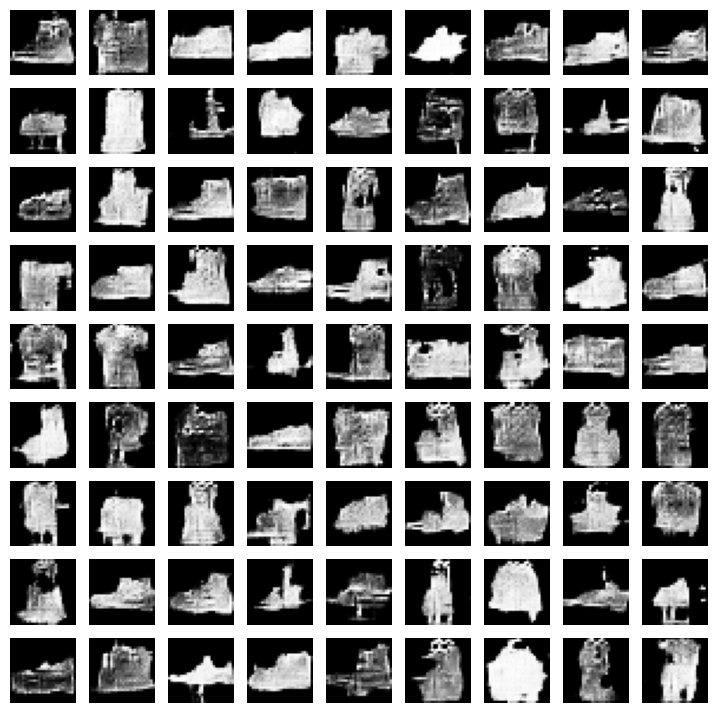

E:29, Loss G:2.3198, Loss D:0.2307, Acc G:%4.61, Acc D:%91.45


In [11]:
# neste exemplo, treinamos ambos por 1 passo
# por isso é comum visualizar as imagens geradas a cada poucas épocas
# alguns juntam as imagens em um vídeo
for epoch in range(30):

  # acumular as perdas e acuracias para calcular a média no fim da época
  dLossSum = 0
  gLossSum = 0
  dAccSum = 0
  gAccSum = 0
  cnt = 0

  # percorrer o dataset lote por lote
  for batch in dataset:

    # treinar o discriminador
    # este bloco poderia ser repetido k vezes
    dLoss = trainDStep(batch)
    dLossSum += dLoss['discriminator_loss']
    dAccSum += dLoss['discriminator_accuracy']

    # treinar o gerador
    gLoss = trainGStep(batch)
    gLossSum += gLoss['generator_loss']
    gAccSum += gLoss['generator_accuracy']

    # incrementar o contador
    cnt += 1

  # exibir o desempenho da época
  print("E:{}, Loss G:{:0.4f}, Loss D:{:0.4f}, Acc G:%{:0.2f}, Acc D:%{:0.2f}".format(
      epoch,
      gLossSum/cnt,
      dLossSum/cnt,
      100 * gAccSum/cnt,
      100 * dAccSum/cnt
  ))

  if epoch % 2 == 0:
    plotImages(generator)

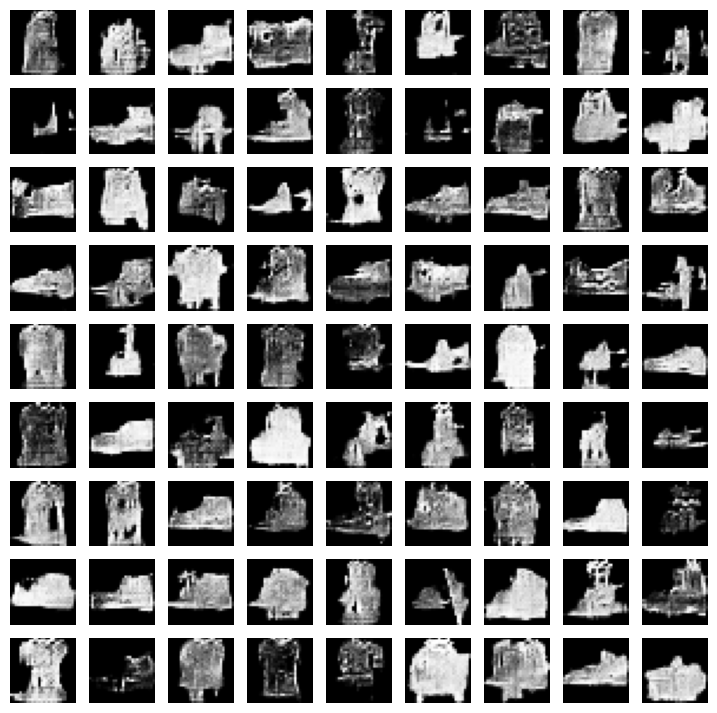

In [12]:
# gerar imagens com o modelo treinado
# note que as amostras parecem da mesma classe; este é o problema de colapso de modo
images = generator(np.random.normal(size=(81, NOISE_DIM)))

# plotar as amostras geradas
from matplotlib import pyplot as plt

plt.figure(figsize=(9, 9))

for i, image in enumerate(images):
    plt.subplot(9,9,i+1)
    plt.imshow(np.squeeze(image, -1), cmap="Greys_r")
    plt.axis('off')

plt.show();